# Oficina FTL 2025 — Emissões atmosféricas e qualidade do ar no seu município

**Três perguntas para explorar com dados públicos**

1. Qual é a fonte majoritária de **MP₂,₅ primário emitido** no município?
   Como se distribuem as emissões de **NOₓ (equivalente em NO₂)**?
2. Quantas estações de monitoramento estão cadastradas no município?
3. Qual é a série histórica de **concentrações observadas** de MP₂,₅
   nas estações disponíveis?

**Ambientes:** Jupyter Notebook e Google Colab (Python 3). Os dados
são baixados automaticamente e reutilizados nas próximas execuções.

> **Interpretação:** os inventários representam taxas de **emissão**
> (ex.: g/s), não **concentrações** (µg/m³). A comparação entre fontes
> utiliza somente um dia de 2019, e não um balanço anual. Para NOₓ,
> as taxas de NO e NO₂ são expressas em massa equivalente de NO₂.

**Fontes:** [IBGE — Malhas Municipais 2025](https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2025/Brasil/BR_Municipios_2025.zip);
[BRAIN — descrição científica](https://essd.copernicus.org/articles/16/2385/2024/);
[relatório interativo de qualidade do ar](https://arquivos.lcqar.ufsc.br/br-airquality-report/intro.html);
[Resolução CONAMA 506/2024](https://conama.mma.gov.br/index.php?option=com_sisconama&view=atonormativo&id=756).

## 0. Preparação

**Instruções:** execute as células em ordem. No Colab, os arquivos
ficam na sessão temporária em `/content`; para mantê-los, é possível
montar o Google Drive e mudar `RAIZ`.

Os downloads podem ocupar bastante espaço. O processamento seleciona
os pixels de interesse antes de carregar os valores de emissão.
**Somente os arquivos de entrada serão gravados automaticamente.**
As linhas de exportação de tabelas e figuras ficarão comentadas.

In [ ]:
%pip -q install numpy pandas matplotlib requests tqdm xarray
%pip -q install netCDF4 geopandas shapely pyproj pyogrio

In [1]:
from collections.abc import Mapping, Sequence
from pathlib import Path
from typing import Any
from urllib.parse import quote
import re
import warnings
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xarray as xr
from IPython.display import display
from pyproj import CRS, Transformer
from requests.adapters import HTTPAdapter
from shapely.geometry import box
from shapely.ops import transform as shp_transform
from tqdm.auto import tqdm
from urllib3.util.retry import Retry

# Pasta de trabalho: no Colab, normalmente corresponde a /content.
RAIZ = Path.cwd()
DIR_MALHA = RAIZ / 'inputs' / 'vectors' / 'ibge_cities_2025'
DIR_EMISSOES = RAIZ / 'inputs' / 'raster' / 'emissions'
DIR_ESTACOES = RAIZ / 'inputs' / 'stations'

# Pastas de exportação opcionais; não serão criadas nesta aula.
DIR_SAIDAS = RAIZ / 'outputs'
DIR_FIGURAS = DIR_SAIDAS / 'figures'
DIR_TABELAS = DIR_SAIDAS / 'tables'

# Os diretórios de entrada são necessários para os downloads.
for pasta in (DIR_MALHA, DIR_EMISSOES, DIR_ESTACOES):
    pasta.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 115, 'axes.grid': False})
print('Diretório do projeto:', RAIZ)

Diretório do projeto: /home/igorvrt/Doutorado/06.Aulas/2025-10_FutureTechLeaders


/home/igorvrt/Doutorado/06.Aulas/2025-10_FutureTechLeaders/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Qual a fonte de emissão majoritária no município?

### 1.1. Escolher o município

Informe abaixo o **código IBGE de 7 dígitos**. Exemplo: Florianópolis (SC) = `4205407`. A mesma escolha será utilizada nas sessões 2 e 3.

Os arquivos representam **um único dia (1º de janeiro de 2019)**, com dados horários. A classificação é uma demonstração didática, **não** representa necessariamente as fontes predominantes em todo o ano.

In [2]:
# ===================== CONFIGURAÇÃO DO ALUNO =====================
CODIGO_IBGE = '4205407'  # Florianópolis/SC: altere para seu município.
ANALISAR_NOX = True      # Exibe também as emissões de NOx (NO2-eq.).
RAIO_TERRA_M = 6_370_000  # Convenção esférica de grades WRF/MCIP.
# ================================================================

CODIGO_IBGE = str(CODIGO_IBGE).strip()
if not re.fullmatch(r'\d{7}', CODIGO_IBGE):
    raise ValueError(
        'Informe um código IBGE municipal com sete algarismos.'
    )
print('Município selecionado:', CODIGO_IBGE)

Município selecionado: 4205407


### 1.2. Baixar e extrair os dados

As emissões incluem **indústria (IND), veículos (BRAVES), queimadas (FINN) e biogênicas (MEGAN)**, em grades preparadas para modelagem da qualidade do ar. A função abaixo não faz o download novamente se um ZIP já existir e estiver íntegro. Em caso de indisponibilidade temporária do servidor, também é possível baixar o ZIP manualmente e colocá-lo na pasta indicada.

In [3]:
URL_MALHA = (
    'https://geoftp.ibge.gov.br/organizacao_do_territorio/'
    'malhas_territoriais/malhas_municipais/municipio_2025/'
    'Brasil/BR_Municipios_2025.zip'
)

URLS_EMISSOES = {
    'Industrial': (
        'https://download.scidb.cn/download?'
        'fileId=e70fec7108bb77c83b78d3e5f4bc2d95&'
        'path=/V2/IND/BR_20X20/'
        'IND2CMAQ_2019_01_01_0000_to_2019_01_02_0000.zip&'
        'fileName=IND2CMAQ_2019_01_01_0000_to_2019_01_02_0000.zip'
    ),
    'Veicular': (
        'https://download.scidb.cn/download?'
        'fileId=08a6ba276c905b45007b7db38119730f&'
        'path=/V2/BRAVES/BR_20X20/'
        'BRAVESdatabase2CMAQ_2019_01_01_0000_to_2019_01_02_0000.zip&'
        'fileName=BRAVESdatabase2CMAQ_2019_01_01_0000_to_2019_01_02_0000.zip'
    ),
    'Queimadas': (
        'https://download.scidb.cn/download?'
        'fileId=ccd19b0aaac0b7be36e3efe473daa51d&'
        'path=/V2/FINN/BR_20X20/'
        'FINNv1.5_2016.CB6r3.NRT.BR_2019.3D.2019-01-01.zip&'
        'fileName=FINNv1.5_2016.CB6r3.NRT.BR_2019.3D.2019-01-01.zip'
    ),
    'Biogênica': (
        'https://download.scidb.cn/download?'
        'fileId=168d07523120b1e204300bd1a6cebc6d&'
        'path=/V2/MEGAN/BR_20X20/'
        'MEGANv31.BR_2019.CB6X.2019001.BDSNP.zip&'
        'fileName=MEGANv31.BR_2019.CB6X.2019001.BDSNP.zip'
    ),
}

# Reutilizamos uma sessão HTTP e repetimos requisições temporariamente
# malsucedidas (por exemplo, erro 503 do servidor de arquivos).
HTTP = requests.Session()
retry = Retry(
    total=3,
    backoff_factor=1.5,
    status_forcelist=[429, 500, 502, 503, 504],
)
HTTP.mount('https://', HTTPAdapter(max_retries=retry))
HTTP.headers.update({'User-Agent': 'Mozilla/5.0 (aula de qualidade do ar)'})


def baixar(
    url: str,
    destino: str | Path,
    validar_zip: bool = False,
) -> Path:
    """Baixar um arquivo somente quando ainda não está disponível.

    Parameters
    ----------
    url : str
        Endereço do arquivo remoto.
    destino : str or pathlib.Path
        Caminho local para guardar o arquivo de entrada.
    validar_zip : bool, default False
        Se verdadeiro, verificar a estrutura ZIP antes de reutilizar
        ou aceitar um download.

    Returns
    -------
    pathlib.Path
        Caminho local do arquivo baixado ou já existente.

    Raises
    ------
    RuntimeError
        Se a transferência falhar ou não retornar um ZIP válido.

    Notes
    -----
    O sufixo ``.part`` impede que arquivos incompletos pareçam
    downloads concluídos. Trata-se de cache de **entrada**.
    """
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)

    # Se o arquivo local já é válido, evitamos tráfego repetido.
    if destino.is_file() and destino.stat().st_size > 0:
        if not validar_zip or zipfile.is_zipfile(destino):
            print('Já existe:', destino.name)
            return destino
        destino.unlink()

    temporario = destino.with_name(destino.name + '.part')
    try:
        with HTTP.get(url, stream=True, timeout=(30, 180)) as resposta:
            resposta.raise_for_status()
            total = int(resposta.headers.get('Content-Length', 0))

            with (
                temporario.open('wb') as arquivo,
                tqdm(
                    total=total or None,
                    unit='B',
                    unit_scale=True,
                    desc=destino.name,
                    leave=False,
                ) as barra,
            ):
                # Download em blocos: não carrega o ZIP na RAM.
                for bloco in resposta.iter_content(chunk_size=1024 * 1024):
                    if bloco:
                        arquivo.write(bloco)
                        barra.update(len(bloco))

        if validar_zip and not zipfile.is_zipfile(temporario):
            raise ValueError('O servidor não retornou um ZIP válido.')
        temporario.replace(destino)
    except Exception as exc:
        temporario.unlink(missing_ok=True)
        raise RuntimeError(
            f'Falha no download de {destino.name}. '
            f'Baixe manualmente o arquivo e salve em {destino}.'
        ) from exc

    return destino


def extrair_zip(arquivo_zip: str | Path, destino: str | Path) -> None:
    """Extrair um ZIP de entrada sem repetir extrações concluídas.

    Parameters
    ----------
    arquivo_zip : str or pathlib.Path
        Arquivo compactado com shapefile ou NetCDF.
    destino : str or pathlib.Path
        Diretório em que os arquivos serão extraídos.

    Returns
    -------
    None
        Arquivos extraídos para ``destino``.

    Raises
    ------
    ValueError
        Se um membro do ZIP apontar para fora do diretório de destino.

    Notes
    -----
    O marcador ``.extracao_concluida`` pertence ao cache dos dados de
    entrada; não é uma exportação dos resultados científicos.
    """
    destino = Path(destino)
    marcador = destino / '.extracao_concluida'
    extensoes = {'.shp', '.nc', '.ncf'}

    ja_extraiu = any(
        arquivo.is_file() and arquivo.suffix.lower() in extensoes
        for arquivo in destino.rglob('*')
    )
    if marcador.exists() and ja_extraiu:
        return

    with zipfile.ZipFile(arquivo_zip) as zip_arquivo:
        destino_absoluto = destino.resolve()
        for membro in zip_arquivo.infolist():
            alvo = (destino / membro.filename).resolve()
            if not alvo.is_relative_to(destino_absoluto):
                raise ValueError('ZIP contém um caminho inseguro.')

        zip_arquivo.extractall(destino)

    marcador.touch()


zip_malha = baixar(
    URL_MALHA,
    DIR_MALHA / 'BR_Municipios_2025.zip',
    validar_zip=True,
)
extrair_zip(zip_malha, DIR_MALHA)

arquivos_fontes = {}
for fonte, url in URLS_EMISSOES.items():
    pasta_fonte = DIR_EMISSOES / fonte.lower()
    nome_zip = url.split('fileName=')[-1]
    zip_emissoes = baixar(
        url,
        pasta_fonte / nome_zip,
        validar_zip=True,
    )
    extrair_zip(zip_emissoes, pasta_fonte)

    # Um ZIP pode conter um ou vários NetCDFs, inclusive .ncf.
    netcdfs = sorted(
        caminho
        for caminho in pasta_fonte.rglob('*')
        if caminho.is_file() and caminho.suffix.lower() in {'.nc', '.ncf'}
    )
    if not netcdfs:
        raise FileNotFoundError(
            f'Nenhum NetCDF da fonte {fonte} encontrado em {pasta_fonte}.'
        )
    arquivos_fontes[fonte] = netcdfs
    print(f'{fonte}: {len(netcdfs)} arquivo(s) NetCDF.')

Industrial: 1 arquivo(s) NetCDF.


Veicular: 1 arquivo(s) NetCDF.


Queimadas: 1 arquivo(s) NetCDF.


Biogênica: 1 arquivo(s) NetCDF.


### 1.3. Ler a malha municipal e verificar a projeção dos NetCDFs

Os NetCDFs preparados para o CMAQ usam frequentemente metadados **Models-3 I/O API** (`GDTYP`, `XORIG`, `YORIG`, `XCELL`, `YCELL`). O script reconhece grades geográficas, Lambert conforme e Mercator equatorial. **Não** é correto supor que a coluna 0 de um raster corresponda a longitude 0: primeiro é necessário converter a grade para suas coordenadas geográficas ou projetadas.

Em cada arquivo, calculamos **a fração da área de cada célula contida no município**. Isso evita perder municípios menores do que o pixel e evita contabilizar integralmente células que apenas interceptam a fronteira municipal. A suposição didática é que a emissão esteja distribuída uniformemente no interior de cada pixel.

In [12]:
shapefiles = list(DIR_MALHA.rglob('*.shp'))
if not shapefiles:
    raise FileNotFoundError('Shapefile municipal não encontrado.')

shp = next(
    (p for p in shapefiles if 'Municipios_2025' in p.name),
    shapefiles[0],
)
municipios = gpd.read_file(shp)
print('Colunas da malha:', list(municipios.columns))

nomes_codigo = {'CD_MUN', 'CD_GEOCMU', 'CD_GEOCODI'}
col_codigo = next(
    (col for col in municipios.columns if col.upper() in nomes_codigo),
    None,
)
if col_codigo is None:
    raise KeyError('A malha não possui a coluna de código municipal.')

# Convertemos o código IBGE em texto, preservando seus sete dígitos.
codigos = (
    municipios[col_codigo]
    .astype(str)
    .str.replace(r'\.0$', '', regex=True)
    .str.zfill(7)
)
municipio = municipios.loc[codigos.eq(CODIGO_IBGE)].copy()

if municipio.empty:
    raise ValueError(f'Código {CODIGO_IBGE} não encontrado na malha.')
if municipio.crs is None:
    raise ValueError('A malha municipal não declara seu CRS.')

municipio = municipio.to_crs('EPSG:4326')
nomes_municipio = {'NM_MUN', 'NM_MUNICIP', 'NOME'}
col_nome = next(
    (col for col in municipio.columns if col.upper() in nomes_municipio),
    None,
)
NOME_MUNICIPIO = (
    str(municipio.iloc[0][col_nome]) if col_nome else CODIGO_IBGE
)

print('Município:', NOME_MUNICIPIO)
print('Código IBGE:', CODIGO_IBGE, '| CRS:', municipio.crs)
colunas_exibicao = [col_codigo] + ([col_nome] if col_nome else [])
display(municipio[colunas_exibicao].head())

Colunas da malha: ['CD_MUN', 'NM_MUN', 'CD_RGI', 'NM_RGI', 'CD_RGINT', 'NM_RGINT', 'CD_UF', 'NM_UF', 'SIGLA_UF', 'CD_REGIAO', 'NM_REGIAO', 'SIGLA_RG', 'CD_CONCURB', 'NM_CONCURB', 'AREA_KM2', 'geometry']
Município: Florianópolis
Código IBGE: 4205407 | CRS: EPSG:4326


,CD_MUN,NM_MUN
3418,4205407,Florianópolis


In [13]:
# Espécies primárias finas do mecanismo químico típico dos inventários.
# Excluímos PMC (fração grossa) e PH2O (água das partículas).
ESPECIES_FINAS = {
    'PAL', 'PCA', 'PCL', 'PEC', 'PFE', 'PK', 'PMG', 'PMN',
    'PMOTHR', 'PNA', 'PNCOM', 'PNH4', 'PNO3', 'POC',
    'PSI', 'PSO4', 'PTI',
}
NOMES_PM25_DIRETO = (
    'PM25', 'PM2_5', 'PM25_TOT', 'PM25_TOTAL', 'PM25TOT',
)


def atributo_ioapi(
    attrs: Mapping[str, Any],
    nome: str,
    padrao: Any = None,
) -> Any:
    """Consultar atributo I/O API aceitando nomes em caixa baixa.

    Parameters
    ----------
    attrs : Mapping[str, Any]
        Metadados globais do NetCDF.
    nome : str
        Nome do atributo a consultar.
    padrao : Any, optional
        Valor usado quando o atributo não existe.

    Returns
    -------
    Any
        Valor do atributo ou ``padrao``.
    """
    return attrs.get(nome, attrs.get(nome.lower(), padrao))


def crs_ioapi(attrs: Mapping[str, Any]) -> CRS:
    """Construir o CRS espacial usando o cabeçalho Models-3 I/O API.

    Parameters
    ----------
    attrs : Mapping[str, Any]
        Atributos globais, incluindo ``GDTYP`` e parâmetros de grade.

    Returns
    -------
    pyproj.CRS
        CRS geográfico, Lambert conforme ou Mercator.

    Raises
    ------
    NotImplementedError
        Se ``GDTYP`` indicar uma projeção não implementada.

    Notes
    -----
    Para as grades projetadas, usamos o raio terrestre configurado em
    ``RAIO_TERRA_M``. Não substituímos a projeção por EPSG:4326.
    """
    tipo = int(atributo_ioapi(attrs, 'GDTYP', -1))
    if tipo == 1:
        return CRS.from_epsg(4326)

    if tipo == 2:
        proj4 = (
            f'+proj=lcc '
            f'+lat_1={float(atributo_ioapi(attrs, "P_ALP"))} '
            f'+lat_2={float(atributo_ioapi(attrs, "P_BET"))} '
            f'+lat_0={float(atributo_ioapi(attrs, "YCENT", 0))} '
            f'+lon_0={float(atributo_ioapi(attrs, "P_GAM"))} '
            f'+R={RAIO_TERRA_M} +units=m +no_defs'
        )
        return CRS.from_proj4(proj4)

    if tipo == 7:
        longitude_central = atributo_ioapi(
            attrs, 'P_GAM', atributo_ioapi(attrs, 'XCENT', 0)
        )
        proj4 = (
            f'+proj=merc '
            f'+lat_ts={float(atributo_ioapi(attrs, "P_ALP", 0))} '
            f'+lon_0={float(longitude_central)} '
            f'+R={RAIO_TERRA_M} +units=m +no_defs'
        )
        return CRS.from_proj4(proj4)

    raise NotImplementedError(
        f'Projeção GDTYP={tipo} não implementada; examine o NetCDF.'
    )


def dimensoes_cmaq(
    ds: xr.Dataset,
) -> tuple[str, str | None, str, str]:
    """Identificar tempo, camada, linha e coluna de um NetCDF CMAQ.

    Parameters
    ----------
    ds : xarray.Dataset
        Conjunto de dados com dimensões espaciais e temporais.

    Returns
    -------
    tuple[str, str | None, str, str]
        Nomes de (tempo, camada, linha, coluna); camada pode faltar.

    Raises
    ------
    ValueError
        Se não for possível localizar as dimensões obrigatórias.
    """
    dimensoes = {nome.upper(): nome for nome in ds.sizes}
    tempo = next(
        (dimensoes[n] for n in ('TSTEP', 'TIME') if n in dimensoes),
        None,
    )
    camada = next(
        (dimensoes[n] for n in ('LAY', 'LEVEL', 'LEV') if n in dimensoes),
        None,
    )
    linha = next(
        (dimensoes[n] for n in ('ROW', 'Y', 'SOUTH_NORTH')
         if n in dimensoes),
        None,
    )
    coluna = next(
        (dimensoes[n] for n in ('COL', 'X', 'WEST_EAST')
         if n in dimensoes),
        None,
    )

    if not tempo or not linha or not coluna:
        raise ValueError(
            f'Dimensões CMAQ não reconhecidas: {dict(ds.sizes)}'
        )
    return tempo, camada, linha, coluna


def janela_e_pesos(
    ds: xr.Dataset,
    geometria_municipal: gpd.GeoDataFrame,
) -> dict[str, Any]:
    """Encontrar os pixels municipais e suas frações de interseção.

    Parameters
    ----------
    ds : xarray.Dataset
        NetCDF com os atributos de origem, resolução e projeção.
    geometria_municipal : geopandas.GeoDataFrame
        Polígono municipal com CRS definido.

    Returns
    -------
    dict[str, Any]
        Dimensões do arquivo, recorte retangular (índices ``i0:i1``
        e ``j0:j1``), CRS, bordas das células e matriz ``pesos``.

    Raises
    ------
    ValueError
        Se não houver pixels interceptando o município.

    Notes
    -----
    ``pesos`` contém a fração da área de cada pixel que pertence ao
    município, entre 0 e 1. Usamos EPSG:6933 (área equivalente) para
    calcular as frações. Pressupõe-se distribuição uniforme dentro de
    cada pixel da grade original.
    """
    tempo, camada, linha, coluna = dimensoes_cmaq(ds)
    crs = crs_ioapi(ds.attrs)

    # XORIG/YORIG são bordas, não coordenadas do centro dos pixels.
    x0 = float(ds.attrs['XORIG'])
    y0 = float(ds.attrs['YORIG'])
    dx = float(ds.attrs['XCELL'])
    dy = float(ds.attrs['YCELL'])
    ncolunas = ds.sizes[coluna]
    nlinhas = ds.sizes[linha]
    xedges = x0 + np.arange(ncolunas + 1) * dx
    yedges = y0 + np.arange(nlinhas + 1) * dy

    # Trabalhamos no mesmo CRS do NetCDF antes de identificar pixels.
    geometria = geometria_municipal.to_crs(crs).geometry.union_all()
    minx, miny, maxx, maxy = geometria.bounds
    indices_coluna = np.flatnonzero(
        (np.minimum(xedges[:-1], xedges[1:]) < maxx)
        & (np.maximum(xedges[:-1], xedges[1:]) > minx)
    )
    indices_linha = np.flatnonzero(
        (np.minimum(yedges[:-1], yedges[1:]) < maxy)
        & (np.maximum(yedges[:-1], yedges[1:]) > miny)
    )
    if len(indices_coluna) == 0 or len(indices_linha) == 0:
        raise ValueError('O município está fora do domínio do NetCDF.')

    i0 = int(indices_linha[0])
    i1 = int(indices_linha[-1]) + 1
    j0 = int(indices_coluna[0])
    j1 = int(indices_coluna[-1]) + 1

    # Um pixel pode tocar o município apenas parcialmente. Por isso,
    # transformamos as áreas para um CRS equivalente antes da divisão.
    transformar_area = Transformer.from_crs(
        crs, CRS.from_epsg(6933), always_xy=True
    ).transform
    pesos = np.zeros((i1 - i0, j1 - j0), dtype=float)

    for i_local, i in enumerate(range(i0, i1)):
        for j_local, j in enumerate(range(j0, j1)):
            celula = box(
                min(xedges[j], xedges[j + 1]),
                min(yedges[i], yedges[i + 1]),
                max(xedges[j], xedges[j + 1]),
                max(yedges[i], yedges[i + 1]),
            )
            intersecao = geometria.intersection(celula)
            if intersecao.is_empty or intersecao.area <= 0:
                continue

            area_intersecao = shp_transform(
                transformar_area, intersecao
            ).area
            area_celula = shp_transform(transformar_area, celula).area
            fracao = area_intersecao / area_celula
            pesos[i_local, j_local] = np.clip(fracao, 0.0, 1.0)

    if not np.any(pesos > 0):
        raise ValueError('Nenhum pixel com interseção municipal positiva.')

    return {
        'tempo': tempo,
        'lay': camada,
        'row': linha,
        'col': coluna,
        'i0': i0,
        'i1': i1,
        'j0': j0,
        'j1': j1,
        'crs': crs,
        'municipio': geometria,
        'pesos': pesos,
        'xedges': xedges[j0:j1 + 1],
        'yedges': yedges[i0:i1 + 1],
    }


def media_24h(
    ds: xr.Dataset,
    nome: str,
    geo: Mapping[str, Any],
) -> np.ndarray:
    """Calcular a média das primeiras 24 horas de uma variável.

    Parameters
    ----------
    ds : xarray.Dataset
        NetCDF que contém a variável de emissão.
    nome : str
        Nome da espécie a processar.
    geo : Mapping[str, Any]
        Informações de recorte produzidas por ``janela_e_pesos``.

    Returns
    -------
    numpy.ndarray
        Matriz 2D de taxas médias (unidade original da variável).

    Raises
    ------
    ValueError
        Se houver menos de 24 tempos ou dimensões extras inesperadas.

    Notes
    -----
    Somamos os níveis verticais, se existirem, antes de fazer a
    média temporal. Ignoramos um eventual 25º registro de fechamento.
    """
    variavel = ds[nome]
    if ds.sizes[geo['tempo']] < 24:
        raise ValueError(f'{nome}: menos de 24 registros de tempo.')

    fatias = {
        geo['tempo']: slice(0, 24),
        geo['row']: slice(geo['i0'], geo['i1']),
        geo['col']: slice(geo['j0'], geo['j1']),
    }
    variavel = variavel.isel(fatias)
    extras = [
        dim for dim in variavel.dims
        if dim not in {geo['tempo'], geo['row'], geo['col']}
    ]

    if extras:
        if len(extras) > 1 or extras[0] != geo['lay']:
            raise ValueError(
                f'Dimensões extras inesperadas em {nome}: {extras}'
            )
        variavel = variavel.sum(dim=extras[0], skipna=True)

    media = variavel.mean(dim=geo['tempo'], skipna=True)
    media = media.transpose(geo['row'], geo['col'])
    return np.asarray(media.to_numpy(), dtype=float)


def unidade_multiplicador(
    unidade: str,
    especie: str,
    poluente: str,
) -> float:
    """Converter a unidade de emissão para o padrão usado na oficina.

    Parameters
    ----------
    unidade : str
        Unidade indicada nos metadados, por exemplo ``g/s`` ou
        ``moles/s``.
    especie : str
        Nome químico da espécie (por exemplo, ``NO`` ou ``PEC``).
    poluente : str
        Agregado desejado: ``PM25`` ou ``NOx``.

    Returns
    -------
    float
        Fator que produz g/h de MP2,5 ou g NO2-equivalente/h de NOx.

    Raises
    ------
    ValueError
        Se a unidade não for reconhecida ou for incompatível.

    Notes
    -----
    NO e NO2 são convertidos para massa equivalente de NO2 usando
    46,0055 g/mol. Isso não significa que NO tenha sido emitido
    quimicamente como NO2.
    """
    normalizada = re.sub(r'\s+', '', str(unidade).lower())
    normalizada = normalizada.replace('second', 's').replace('sec', 's')
    normalizada = normalizada.replace('grams', 'g').replace('gram', 'g')
    normalizada = normalizada.replace('moles', 'mol').replace('mole', 'mol')

    if not normalizada:
        warnings.warn(
            f'Unidade ausente para {especie}; assumindo g/s.',
            stacklevel=2,
        )
        normalizada = 'g/s'

    notacoes_por_segundo = ('/s', 's-1', 's^-1', 's**-1')
    if not any(sufixo in normalizada for sufixo in notacoes_por_segundo):
        raise ValueError(
            f'Unidade temporal não reconhecida: {unidade!r} ({especie}).'
        )

    # Emissões particuladas são informadas em massa, enquanto gases
    # podem ser expressos em mol/s (precisando de massa molar).
    if normalizada.startswith('kg'):
        massa_para_g = 1000.0
    elif normalizada.startswith('mg'):
        massa_para_g = 0.001
    elif normalizada.startswith('g'):
        massa_para_g = 1.0
    elif normalizada.startswith('mol'):
        massa_para_g = None
    else:
        raise ValueError(
            f'Unidade desconhecida para {especie}: {unidade!r}'
        )

    if poluente == 'PM25':
        if massa_para_g is None:
            raise ValueError(
                f'MP2,5 em mol/s sem massa molar definida: {especie}'
            )
        return massa_para_g * 3600

    if poluente == 'NOx':
        if especie not in {'NO', 'NO2'}:
            raise ValueError(f'Espécie de NOx não reconhecida: {especie}')

        mm_no2 = 46.0055  # g/mol
        mm_original = 30.006 if especie == 'NO' else mm_no2
        if massa_para_g is None:
            return mm_no2  # mol/s -> g NO2-equivalente/s
        return massa_para_g * mm_no2 / mm_original * 3600

    raise ValueError(f'Poluente inválido: {poluente}')


def estatisticas_municipais(
    matriz: np.ndarray,
    pesos: np.ndarray,
) -> dict[str, float]:
    """Resumir valores por pixel e taxa de emissão municipal.

    Parameters
    ----------
    matriz : numpy.ndarray
        Taxas de emissão médias (g/s) por célula da grade.
    pesos : numpy.ndarray
        Fração de cada célula contida no município, de 0 a 1.

    Returns
    -------
    dict[str, float]
        ``media`` ponderada por área, ``mediana``, ``maximo``,
        ``minimo`` e ``total`` municipal estimado.

    Notes
    -----
    Mediana, máximo e mínimo usam os pixels interceptados sem pesos;
    ``total`` soma a taxa de cada célula vezes sua fração municipal.
    """
    valido = (pesos > 0) & np.isfinite(matriz)
    if not valido.any():
        return {
            chave: np.nan
            for chave in ('media', 'mediana', 'maximo', 'minimo', 'total')
        }

    valores = matriz[valido]
    fracao_area = pesos[valido]
    return {
        'media': float(np.average(valores, weights=fracao_area)),
        'mediana': float(np.median(valores)),
        'maximo': float(np.max(valores)),
        'minimo': float(np.min(valores)),
        'total': float(np.sum(valores * fracao_area)),
    }

### 1.4. Reconstruir o MP₂,₅ primário e calcular as estatísticas

**Método:** em cada fonte, selecionamos as espécies de partículas finas
presentes e somamos as taxas de emissão (g/s). `PMC` (partículas grossas)
não é incluído. Quando o NetCDF oferece um total explícito `PM25`,
preferimos esse total para evitar dupla contagem.

Também calculamos **NOₓ como massa equivalente de NO₂**, a partir de
NO e NO₂. Quando as espécies estão em mol/s, a conversão utiliza a
massa molar do NO₂ (46,0055 g/mol).

Depois de somar camadas verticais, calculamos a média das **primeiras
24 horas**, desconsiderando eventual registro extra de fechamento.

O **total municipal estimado** resulta da soma das taxas de emissão
por pixel multiplicadas pela fração de sua área no município. A média
é ponderada por essas frações; mediana, mínimo e máximo descrevem os
pixels com interseção positiva.

> **Limitação:** os resultados descrevem as espécies disponíveis no
> inventário de um dia. Uma espécie ausente não é tomada como zero.
> Inventários com mecanismos químicos diferentes devem ser comparados
> com cuidado.

In [14]:
def processar_fonte(
    fonte: str,
    caminhos: Sequence[Path],
    municipio: gpd.GeoDataFrame,
    incluir_nox: bool = True,
) -> dict[str, Any]:
    """Processar os NetCDFs de uma fonte emissora para um município.

    Parameters
    ----------
    fonte : str
        Nome da fonte, como ``Veicular`` ou ``Queimadas``.
    caminhos : Sequence[pathlib.Path]
        Arquivos NetCDF pertencentes à fonte.
    municipio : geopandas.GeoDataFrame
        Geometria do município escolhido.
    incluir_nox : bool, default True
        Se verdadeiro, calcular NOx em NO2-equivalente.

    Returns
    -------
    dict[str, Any]
        Fonte, grade de referência, matrizes de PM25 e NOx, e espécies
        efetivamente encontradas.

    Raises
    ------
    ValueError
        Se os arquivos não tiverem grades compatíveis entre si.

    Notes
    -----
    Espécies repetidas entre arquivos de uma mesma fonte não são
    somadas duas vezes. Um total de MP2,5 explícito tem prioridade
    sobre a soma dos componentes individuais.
    """
    dados = {'PM25': None, 'NOx': None}
    registro_especies = {'PM25': set(), 'NOx': set()}
    geo_base = None

    for caminho in caminhos:
        with xr.open_dataset(
            caminho,
            engine='netcdf4',
            decode_times=False,
        ) as ds:
            geo = janela_e_pesos(ds, municipio)

            # Os arquivos da mesma fonte devem compartilhar a grade.
            if geo_base is None:
                geo_base = geo
            else:
                for nome in ('pesos', 'xedges', 'yedges'):
                    if not np.allclose(
                        geo_base[nome], geo[nome], atol=1e-5
                    ):
                        raise ValueError(
                            f'Grades diferentes nos NetCDFs de {fonte}.'
                        )

            # Nomes químicos em caixa alta para facilitar a busca.
            lookup = {nome.upper(): nome for nome in ds.data_vars}
            pm_direto = next(
                (nome for nome in NOMES_PM25_DIRETO if nome in lookup),
                None,
            )
            especies_pm = (
                [pm_direto] if pm_direto
                else sorted(ESPECIES_FINAS & set(lookup))
            )
            especies_nox = (
                [nome for nome in ('NO', 'NO2') if nome in lookup]
                if incluir_nox else []
            )

            for poluente, especies in (
                ('PM25', especies_pm),
                ('NOx', especies_nox),
            ):
                for especie in especies:
                    if especie in registro_especies[poluente]:
                        warnings.warn(
                            f'{fonte}: espécie {especie} repetida; '
                            'não será somada novamente.',
                            stacklevel=2,
                        )
                        continue

                    nome_variavel = lookup[especie]
                    unidade = ds[nome_variavel].attrs.get('units', '')
                    fator = unidade_multiplicador(
                        unidade, especie, poluente
                    )
                    matriz_media = (
                        media_24h(ds, nome_variavel, geo) * fator
                    )

                    if dados[poluente] is None:
                        dados[poluente] = np.zeros_like(
                            matriz_media, dtype=float
                        )
                    dados[poluente] += matriz_media
                    registro_especies[poluente].add(especie)

    if geo_base is None:
        raise ValueError(f'Nenhum NetCDF processado para {fonte}.')

    return {
        'fonte': fonte,
        'geo': geo_base,
        'dados': dados,
        'especies': {
            chave: sorted(valores)
            for chave, valores in registro_especies.items()
        },
    }


resultados_emissoes = {}
linhas_resumo = []
for fonte, caminhos in arquivos_fontes.items():
    print('Processando:', fonte)
    resultado = processar_fonte(
        fonte,
        caminhos,
        municipio,
        incluir_nox=ANALISAR_NOX,
    )
    resultados_emissoes[fonte] = resultado

    for poluente, matriz in resultado['dados'].items():
        if matriz is None:
            print(f'  {poluente}: nenhuma espécie identificada.')
            continue

        estatisticas = estatisticas_municipais(
            matriz, resultado['geo']['pesos']
        )
        linhas_resumo.append({
            'fonte': fonte,
            'poluente': poluente,
            # 'especies': ', '.join(resultado['especies'][poluente]),
            **estatisticas,
        })

resumo_emissoes = pd.DataFrame(linhas_resumo)
if resumo_emissoes.empty:
    raise RuntimeError(
        'Não foram encontradas espécies de MP2,5 ou NOx nos NetCDFs.'
    )

# Exportação opcional (descomente para guardar os resultados):
# DIR_TABELAS.mkdir(parents=True, exist_ok=True)
# resumo_emissoes.to_csv(
#     DIR_TABELAS / f'emissoes_{CODIGO_IBGE}_2019-01-01.csv',
#     index=False,
# )

print('MP2,5: g/h por pixel | NOx: g NO2-equivalente/h por pixel')
display(resumo_emissoes.round(5))

Processando: Industrial
Processando: Veicular
Processando: Queimadas
Processando: Biogênica
  PM25: nenhuma espécie identificada.
MP2,5: g/h por pixel | NOx: g NO2-equivalente/h por pixel


,fonte,poluente,media,mediana,maximo,minimo,total
0,Industrial,PM25,0.05324,0.00000,2.18112,0.0,0.11449
1,Industrial,NOx,0.00432,0.00000,0.17698,0.0,0.00929
2,Veicular,PM25,339115.23652,116126.56883,608276.87556,0.0,729216.29437
3,Veicular,NOx,279.68543,100.59364,469.44278,0.0,601.42143
4,Queimadas,PM25,0.00000,0.00000,0.00000,0.0,0.00000
5,Queimadas,NOx,0.00000,0.00000,0.00000,0.0,0.00000
6,Biogênica,NOx,0.40351,0.00000,2.80990,0.0,0.86768


### 1.5. Mapas e identificação da fonte majoritária

Os mapas apresentam as médias de 24 horas, com células recortadas pela
interseção municipal. Usaremos uma mesma escala de cores para cada
poluente, permitindo comparar as fontes.

**Atenção:** se o município é menor que a célula de 20 km, a
representação espacial permanece limitada pela resolução do inventário.

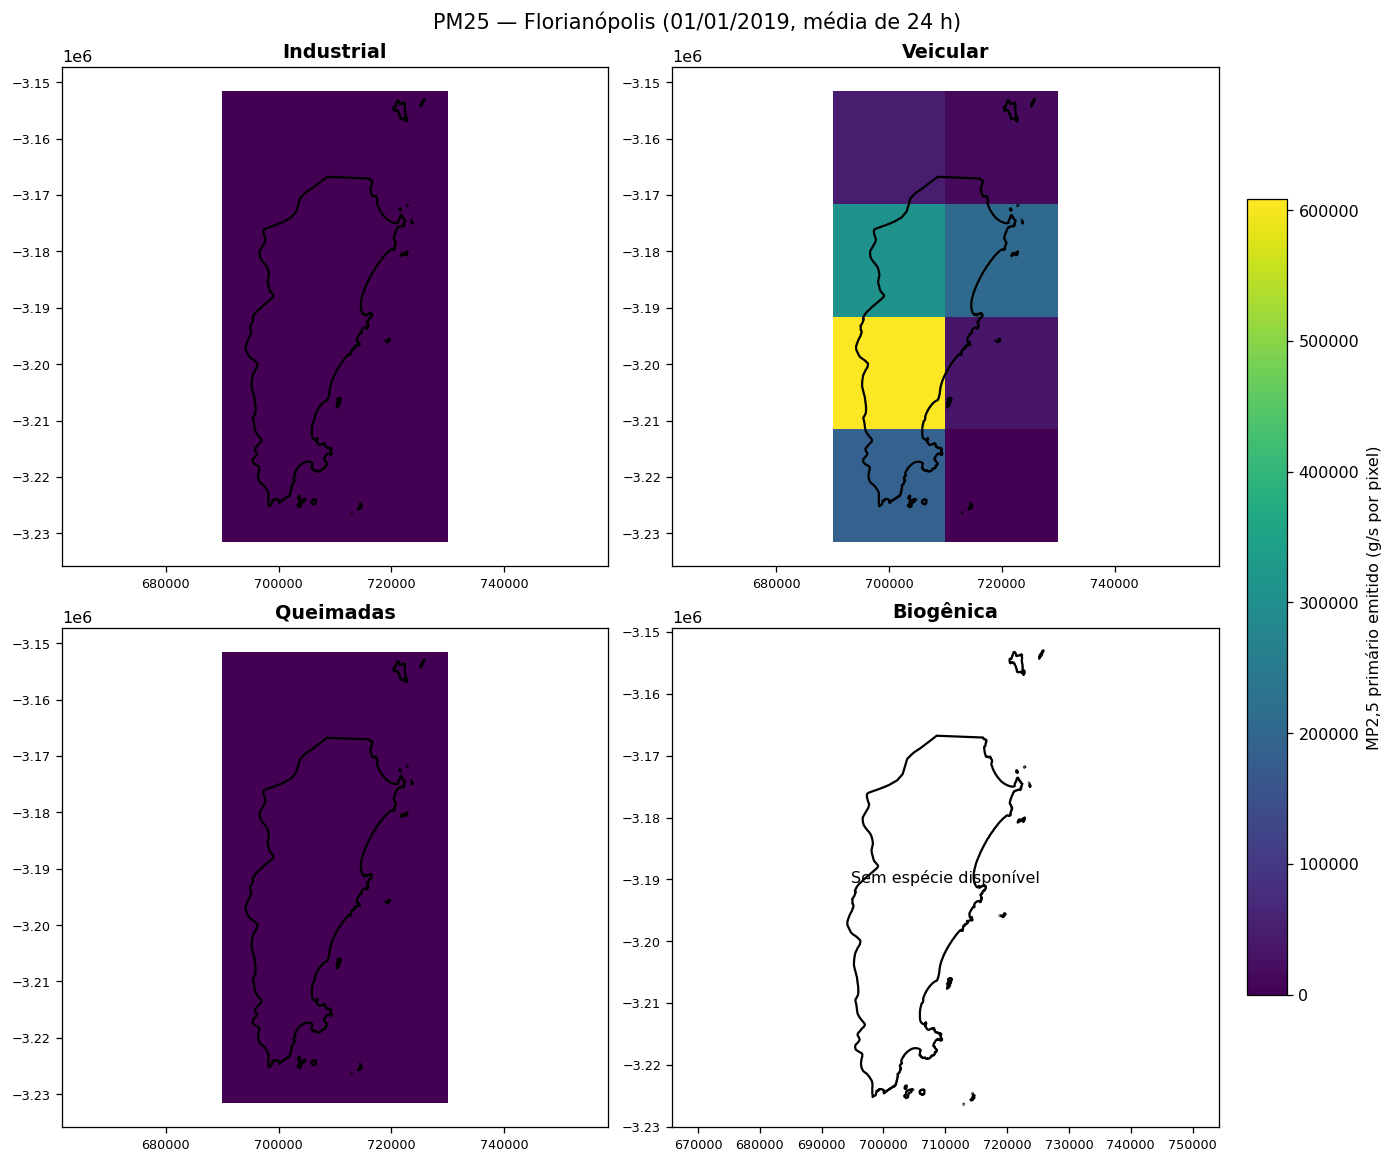

,fonte,total,media,mediana,maximo,minimo
2,Veicular,729216.294371,339115.236521,116126.568828,608276.875556,0.0
0,Industrial,0.114485,0.053240,0.000000,2.181120,0.0
4,Queimadas,0.000000,0.000000,0.000000,0.000000,0.0


Comparação incompleta: há fontes sem MP2,5 identificado.
Fonte com maior taxa municipal de MP2,5: Veicular


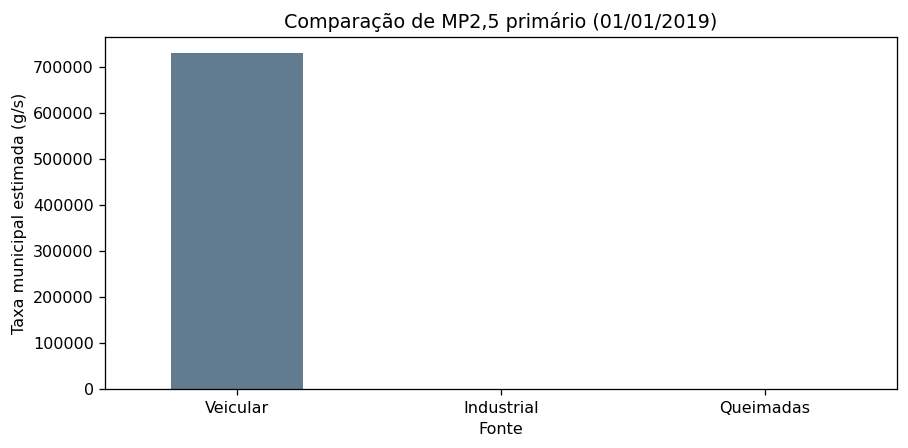

In [16]:
def plotar_fontes(
    poluente: str,
    unidade: str,
    rotulo_arquivo: str,
) -> None:
    """Exibir mapas das quatro fontes numa escala de cores comum.

    Parameters
    ----------
    poluente : str
        Variável agregada a representar, ``PM25`` ou ``NOx``.
    unidade : str
        Texto da unidade da barra de cores.
    rotulo_arquivo : str
        Nome-base para uma exportação opcional (desativada na aula).

    Returns
    -------
    None
        Figura apresentada diretamente no notebook.

    Notes
    -----
    Pixels sem interseção municipal ficam mascarados. As bordas do
    município são reprojetadas para o CRS da grade correspondente.
    """
    fontes = list(resultados_emissoes)
    valores = [
        item['dados'][poluente]
        for item in resultados_emissoes.values()
        if item['dados'][poluente] is not None
    ]
    if not valores:
        print(f'Nenhuma emissão disponível para {poluente}.')
        return

    vmax = max(float(np.nanmax(valor)) for valor in valores)
    fig, eixos = plt.subplots(
        2, 2, figsize=(12, 10), constrained_layout=True
    )
    cores = plt.colormaps['viridis'].copy()
    cores.set_bad('#eeeeee')
    ultimo_mapa = None

    for ax, fonte in zip(eixos.flat, fontes):
        resultado = resultados_emissoes[fonte]
        geo = resultado['geo']
        matriz = resultado['dados'][poluente]

        if matriz is None:
            ax.text(
                0.5, 0.5, 'Sem espécie disponível',
                ha='center', va='center', transform=ax.transAxes,
            )
        else:
            # A máscara altera apenas a exibição: não muda os valores.
            recorte = np.ma.masked_where(geo['pesos'] <= 0, matriz)
            ultimo_mapa = ax.pcolormesh(
                geo['xedges'], geo['yedges'], recorte,
                cmap=cores, vmin=0, vmax=vmax or 1, shading='flat',
            )

        municipio.to_crs(geo['crs']).boundary.plot(
            ax=ax, color='black', linewidth=1.4
        )
        ax.set_title(fonte, weight='bold')
        ax.set_aspect('equal', adjustable='datalim')
        ax.tick_params(labelsize=8)

    if ultimo_mapa is not None:
        fig.colorbar(
            ultimo_mapa, ax=eixos, shrink=0.75,
            label=unidade, pad=0.025,
        )

    fig.suptitle(
        f'{poluente} — {NOME_MUNICIPIO} '
        '(01/01/2019, média de 24 h)',
        fontsize=13,
    )

    # Exportação opcional (deixe comentada durante a oficina):
    # DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
    # fig.savefig(
    #     DIR_FIGURAS / f'{rotulo_arquivo}_{CODIGO_IBGE}.png',
    #     dpi=180, bbox_inches='tight',
    # )
    plt.show()


plotar_fontes(
    'PM25', 'MP2,5 primário emitido (g/s por pixel)', 'mapa_pm25'
)

pm25_resumo = resumo_emissoes.loc[
    resumo_emissoes['poluente'].eq('PM25')
].copy()
pm25_resumo = pm25_resumo.sort_values('total', ascending=False)

if pm25_resumo.empty:
    print('Não há espécies de MP2,5 para identificar a fonte majoritária.')
else:
    colunas_ranking = [
        'fonte', 'total', 'media', 'mediana',
        'maximo', 'minimo',
        # 'especies',
    ]
    display(pm25_resumo[colunas_ranking].round(6))

    if len(pm25_resumo) != len(resultados_emissoes):
        print('Comparação incompleta: há fontes sem MP2,5 identificado.')

    fonte_majoritaria = pm25_resumo.iloc[0]['fonte']
    print('Fonte com maior taxa municipal de MP2,5:', fonte_majoritaria)

    ax = pm25_resumo.plot.bar(
        x='fonte', y='total', legend=False,
        figsize=(8, 4), color='#617b91',
    )
    ax.set_ylabel('Taxa municipal estimada (g/s)')
    ax.set_xlabel('Fonte')
    ax.set_title('Comparação de MP2,5 primário (01/01/2019)')
    plt.xticks(rotation=0)
    plt.tight_layout()

    # Exportação opcional:
    # DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
    # plt.savefig(
    #     DIR_FIGURAS / f'ranking_pm25_{CODIGO_IBGE}.png',
    #     dpi=180,
    # )
    plt.show()

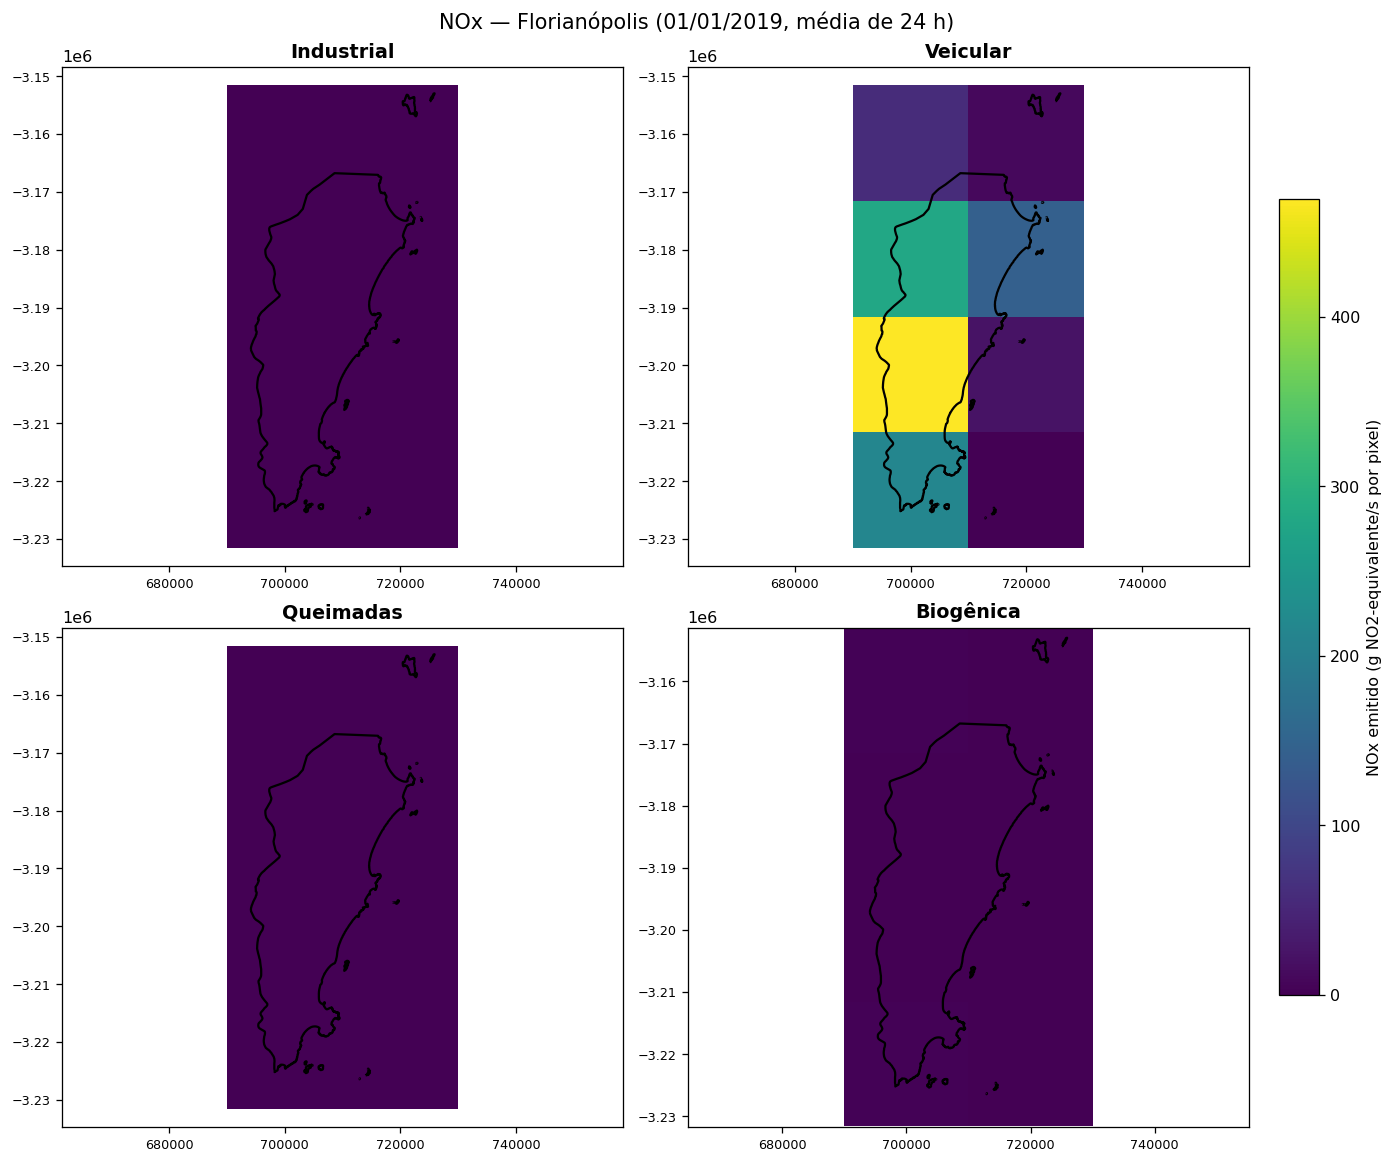

In [17]:
if ANALISAR_NOX:
    plotar_fontes(
        'NOx',
        'NOx emitido (g NO2-equivalente/s por pixel)',
        'mapa_nox',
    )

## 2. Quantas estações estão em seu município?

O **MonitorAr** é uma importante plataforma de acesso a informações de monitoramento no Brasil. Nesta aula, utilizaremos o **banco estendido de monitoramento compilado para os Relatórios Anuais de Acompanhamento da Qualidade do Ar de 2024 e 2025**. Essa base reúne informações de diferentes fontes, como órgãos estaduais e redes adicionais, incluindo estações indicativas.

Vamos carregar o cadastro, selecionar as colunas solicitadas e construir um `GeoDataFrame` a partir de longitude/latitude, no **EPSG:4326**. O cadastro pode ter **mais de uma linha por estação física** (por exemplo, uma por poluente); por isso, a contagem de estações será deduplicada pelo identificador da instalação (parte do ID sem o sufixo de poluente).

**Atenção:** ter uma estação no cadastro não implica que ela esteja ativa, que tenha MP₂,₅ ou que sua série histórica esteja disponível. Estações de referência e indicativas não têm necessariamente a mesma finalidade regulatória.

In [18]:
URL_ESTACOES = (
    'https://arquivos.lcqar.ufsc.br/data/databases/'
    'stations/Monitoramento_QAr_BR.csv'
)
csv_estacoes = baixar(
    URL_ESTACOES, DIR_ESTACOES / 'Monitoramento_QAr_BR.csv'
)
metadados = pd.read_csv(
    csv_estacoes,
    sep=None,
    engine='python',
    dtype=str,
    encoding='utf-8-sig',
)
metadados.columns = metadados.columns.str.strip().str.upper()

COLUNAS = [
    'UF', 'CIDADE', 'CD_MUN', 'ID_MMA_COMPLETO', 'CATEGORIA',
    'POLUENTE', 'STATUS', 'LATITUDE', 'LONGITUDE', 'BASE_DADOS',
]
faltantes = sorted(set(COLUNAS) - set(metadados.columns))
if faltantes:
    raise KeyError(f'Colunas ausentes no cadastro: {faltantes}')
metadados = metadados[COLUNAS].copy()


def normalizar_codigo(valor: Any) -> str:
    """Normalizar um código IBGE municipal para sete dígitos.

    Parameters
    ----------
    valor : Any
        Código lido do CSV como texto ou número.

    Returns
    -------
    str
        Código com sete caracteres quando o valor é numérico.
    """
    codigo = re.sub(r'\.0$', '', str(valor).strip())
    return codigo.zfill(7) if codigo.isdigit() else codigo


metadados['CD_MUN'] = metadados['CD_MUN'].map(normalizar_codigo)

# Alguns CSVs usam vírgula decimal. Normalizamos antes do GeoDataFrame.
for coluna in ('LATITUDE', 'LONGITUDE'):
    metadados[coluna] = pd.to_numeric(
        metadados[coluna].str.replace(',', '.', regex=False),
        errors='coerce',
    )
coordenadas_validas = (
    metadados['LATITUDE'].between(-90, 90)
    & metadados['LONGITUDE'].between(-180, 180)
)
print('Registros no cadastro:', len(metadados))
print('Registros com coordenadas válidas:', coordenadas_validas.sum())

registros_geograficos = metadados.loc[coordenadas_validas].copy()
gdf_estacoes = gpd.GeoDataFrame(
    registros_geograficos,
    geometry=gpd.points_from_xy(
        registros_geograficos['LONGITUDE'],
        registros_geograficos['LATITUDE'],
    ),
    crs='EPSG:4326',
)

# Selecionamos pelo código municipal, inclusive estações sem posição.
estacoes_mun = metadados.loc[
    metadados['CD_MUN'].eq(CODIGO_IBGE)
].copy()
gdf_estacoes_mun = gdf_estacoes.loc[
    gdf_estacoes['CD_MUN'].eq(CODIGO_IBGE)
].copy()

# O identificador completo termina com três dígitos de poluente;
# removê-los permite contar a instalação física uma única vez.
for tabela in (estacoes_mun, gdf_estacoes_mun):
    tabela['ID_ESTACAO_FISICA'] = (
        tabela['ID_MMA_COMPLETO']
        .str.strip()
        .str.replace(r'\d{3}$', '', regex=True)
    )

qtd_fisicas = estacoes_mun['ID_ESTACAO_FISICA'].nunique()
qtd_mapeaveis = gdf_estacoes_mun['ID_ESTACAO_FISICA'].nunique()
print(
    f'{NOME_MUNICIPIO}: {qtd_fisicas} estação(ões) física(s); '
    f'{qtd_mapeaveis} com coordenadas válidas; '
    f'{len(estacoes_mun)} registros por poluente.'
)
display(estacoes_mun[COLUNAS + ['ID_ESTACAO_FISICA']])

# Exportação opcional do mapa vetorial (GeoJSON):
# if not gdf_estacoes_mun.empty:
#     DIR_TABELAS.mkdir(parents=True, exist_ok=True)
#     gdf_estacoes_mun.to_file(
#         DIR_TABELAS / f'estacoes_{CODIGO_IBGE}.geojson',
#         driver='GeoJSON',
#     )

Registros no cadastro: 2337
Registros com coordenadas válidas: 2322
Florianópolis: 1 estação(ões) física(s); 1 com coordenadas válidas; 5 registros por poluente.


,UF,CIDADE,CD_MUN,ID_MMA_COMPLETO,CATEGORIA,POLUENTE,STATUS,LATITUDE,LONGITUDE,BASE_DADOS,ID_ESTACAO_FISICA
1892,SC,Florianopolis,4205407,SC0004RA002,Referencia,MP25,Ativa,-27.599304,-48.519236,True,SC0004RA
1893,SC,Florianopolis,4205407,SC0004RA017,Referencia,NO,Ativa,-27.599304,-48.519236,True,SC0004RA
1894,SC,Florianopolis,4205407,SC0004RA004,Referencia,NO2,Ativa,-27.599304,-48.519236,True,SC0004RA
1895,SC,Florianopolis,4205407,SC0004RA018,Referencia,NOX,Ativa,-27.599304,-48.519236,True,SC0004RA
1896,SC,Florianopolis,4205407,SC0004RA005,Referencia,O3,Ativa,-27.599304,-48.519236,True,SC0004RA


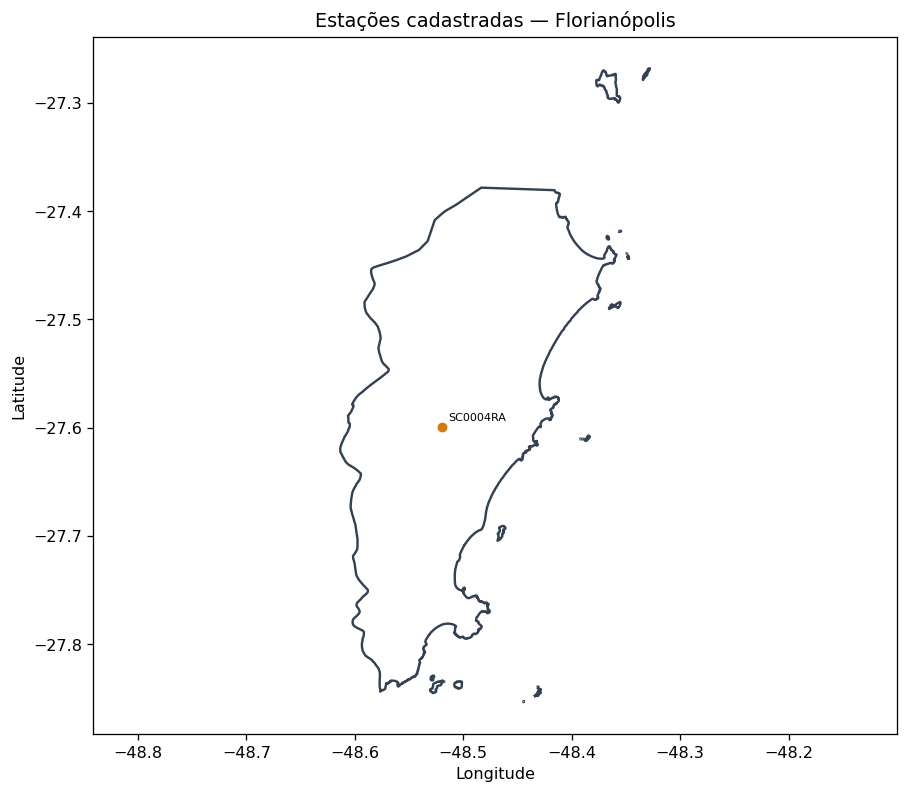

In [19]:
fig, ax = plt.subplots(figsize=(8, 7))
municipio.boundary.plot(ax=ax, color='#334155', linewidth=1.5)

if not gdf_estacoes_mun.empty:
    # Uma linha por estação física, mesmo que ela monitore vários gases.
    sem_duplicar = gdf_estacoes_mun.drop_duplicates(
        'ID_ESTACAO_FISICA'
    )
    sem_duplicar.plot(
        ax=ax, markersize=45, color='#d97706',
        edgecolor='white', linewidth=0.5,
    )
    for _, registro in sem_duplicar.iterrows():
        ax.annotate(
            str(registro['ID_ESTACAO_FISICA']),
            (registro.geometry.x, registro.geometry.y),
            xytext=(4, 4), textcoords='offset points', fontsize=7,
        )
else:
    ax.text(
        0.5, 0.5, 'Nenhuma estação com coordenadas válidas',
        transform=ax.transAxes, ha='center', va='center',
    )

ax.set(
    title=f'Estações cadastradas — {NOME_MUNICIPIO}',
    xlabel='Longitude',
    ylabel='Latitude',
)
ax.set_aspect('equal', adjustable='datalim')
plt.tight_layout()

# Exportação opcional:
# DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
# plt.savefig(DIR_FIGURAS / f'estacoes_{CODIGO_IBGE}.png', dpi=180)
plt.show()

**Alternativa interativa:** a mesma exploração de estações pode ser realizada visualmente na [versão digital interativa do Relatório Anual de Acompanhamento da Qualidade do Ar](https://arquivos.lcqar.ufsc.br/br-airquality-report/intro.html), sem necessidade de programar.

## 3. Qual a série histórica de MP₂,₅ das estações do município?

O repositório público mantém os CSVs por poluente e estação no caminho:

`https://arquivos.lcqar.ufsc.br/data/databases/stations/MQAr_averages/24/MP25/{ID_MMA_COMPLETO}.csv`

Nesta seção, selecionamos apenas os IDs que correspondem a **MP₂,₅**, filtramos `REP_DIA == True`, convertemos `DATETIME` em data e calculamos **uma média por dia** em caso de registros duplicados. A base já está no diretório de agregados de 24 horas; não estamos calculando médias de 24 horas a partir de dados horários brutos.

Para comparação: a **Resolução CONAMA nº 506/2024** estabelece, para MP₂,₅, **PI-2 diário = 50 µg/m³** e **PI-2 anual = 17 µg/m³** (em vigor desde 01/01/2025); **20 µg/m³ é o antigo PI-1 anual**, também exibido no gráfico para fins didáticos. Aplicar padrão vigente a anos históricos é uma **comparação retrospectiva**, não significa que esse padrão estava em vigor na época. Médias anuais com baixa cobertura de dias devem ser interpretadas com cautela.

In [20]:
BASE_SERIES = (
    'https://arquivos.lcqar.ufsc.br/data/databases/stations/'
    'MQAr_averages/24/MP25/'
)
PI2_DIA = 50.0
PI2_ANO = 17.0
PI1_ANO = 20.0


def identificador_pm25(valor: Any) -> bool:
    """Reconhecer diferentes grafias de MP2,5 no cadastro.

    Parameters
    ----------
    valor : Any
        Valor da coluna ``POLUENTE`` de uma estação.

    Returns
    -------
    bool
        Verdadeiro para MP2,5, MP25, PM2.5 e grafias equivalentes.
    """
    texto = re.sub(r'[^A-Z0-9]', '', str(valor).upper())
    return ('MP25' in texto) or ('PM25' in texto)


registros_mp25 = estacoes_mun.loc[
    estacoes_mun['POLUENTE'].map(identificador_pm25)
].drop_duplicates('ID_MMA_COMPLETO').copy()

if registros_mp25.empty and not estacoes_mun.empty:
    print('Nenhum poluente classificado como MP2,5.')
    print('Confira os nomes disponíveis na coluna POLUENTE:')
    print(sorted(estacoes_mun['POLUENTE'].dropna().unique().tolist()))
else:
    print('Séries potenciais de MP2,5:', len(registros_mp25))
    colunas_serie = [
        'ID_MMA_COMPLETO', 'CIDADE', 'CATEGORIA',
        'STATUS', 'BASE_DADOS',
    ]
    display(registros_mp25[colunas_serie])

Séries potenciais de MP2,5: 1


,ID_MMA_COMPLETO,CIDADE,CATEGORIA,STATUS,BASE_DADOS
1892,SC0004RA002,Florianopolis,Referencia,Ativa,True


In [21]:
def eh_true(valor: Any) -> bool:
    """Converter representações textuais de verdadeiro para ``bool``.

    Parameters
    ----------
    valor : Any
        Valor da coluna ``REP_DIA`` no CSV de medições.

    Returns
    -------
    bool
        Verdadeiro para ``True``, ``1``, ``sim``, ``yes`` e ``t``.
    """
    verdadeiro = {'true', '1', 'sim', 'yes', 't', 'verdadeiro'}
    return str(valor).strip().casefold() in verdadeiro


def ler_serie_pm25(id_completo: str) -> pd.DataFrame | None:
    """Obter e filtrar as médias diárias de MP2,5 de uma estação.

    Parameters
    ----------
    id_completo : str
        Identificador da série no cadastro ``ID_MMA_COMPLETO``.

    Returns
    -------
    pandas.DataFrame or None
        Datas, concentrações diárias representativas (µg/m³) e ID;
        ``None`` quando a série é indisponível ou não é utilizável.

    Raises
    ------
    ValueError
        Se o identificador contiver caracteres inesperados.

    Notes
    -----
    O repositório já contém médias de 24 horas. Aplicamos
    ``REP_DIA`` antes de agrupar eventuais datas repetidas.
    """
    id_completo = str(id_completo).strip()
    if not re.fullmatch(r'[A-Za-z0-9_-]+', id_completo):
        raise ValueError(f'ID de estação inválido: {id_completo!r}')

    arquivo = (
        DIR_ESTACOES / 'MQAr_averages' / '24' / 'MP25'
        / f'{id_completo}.csv'
    )
    url = BASE_SERIES + quote(id_completo) + '.csv'
    try:
        baixar(url, arquivo)
    except RuntimeError as exc:
        print(f'Série indisponível: {id_completo} | {exc}')
        return None

    try:
        dados = pd.read_csv(
            arquivo,
            sep=None,
            engine='python',
            encoding='utf-8-sig',
            dtype=str,
        )
    except Exception as exc:
        warnings.warn(
            f'Não foi possível ler a série {id_completo}: {exc}',
            stacklevel=2,
        )
        return None

    dados.columns = dados.columns.str.strip().str.upper()
    colunas_necessarias = {'DATETIME', 'VALOR', 'REP_DIA'}
    faltantes = sorted(colunas_necessarias - set(dados.columns))
    if faltantes:
        warnings.warn(
            f'{id_completo}: faltam colunas {faltantes}.',
            stacklevel=2,
        )
        return None

    # A representatividade é fornecida pela base, não inferida aqui.
    dados = dados.loc[dados['REP_DIA'].map(eh_true)].copy()
    dados['data'] = pd.to_datetime(
        dados['DATETIME'], errors='coerce', dayfirst=False
    ).dt.normalize()
    dados['VALOR'] = pd.to_numeric(
        dados['VALOR'].str.replace(',', '.', regex=False),
        errors='coerce',
    )
    dados = dados.dropna(subset=['data', 'VALOR'])
    dados = dados.loc[dados['VALOR'] >= 0]

    if dados.empty:
        print(f'{id_completo}: sem médias diárias representativas.')
        return None

    # Em caso de duplicidade de data, calculamos uma única média.
    serie = (
        dados.groupby('data', as_index=False)['VALOR']
        .mean()
        .rename(columns={'VALOR': 'MP25_UG_M3'})
        .sort_values('data')
    )
    serie['ID_MMA_COMPLETO'] = id_completo
    return serie


series_disponiveis = []
for codigo_estacao in registros_mp25['ID_MMA_COMPLETO'].dropna().unique():
    serie = ler_serie_pm25(codigo_estacao)
    if serie is not None:
        series_disponiveis.append(serie)

if series_disponiveis:
    serie_diaria = pd.concat(series_disponiveis, ignore_index=True)

    # Exportação opcional dos valores diários:
    # DIR_TABELAS.mkdir(parents=True, exist_ok=True)
    # serie_diaria.to_csv(
    #     DIR_TABELAS / f'mp25_diario_{CODIGO_IBGE}.csv',
    #     index=False,
    # )

    numero_estacoes = serie_diaria['ID_MMA_COMPLETO'].nunique()
    print(
        f'{numero_estacoes} estação(ões) com séries diárias; '
        f'{len(serie_diaria)} médias representativas.'
    )
    display(serie_diaria.head())
else:
    serie_diaria = pd.DataFrame(
        columns=['data', 'MP25_UG_M3', 'ID_MMA_COMPLETO']
    )
    print('Nenhuma série diária disponível para o município.')

1 estação(ões) com séries diárias; 53 médias representativas.


,data,MP25_UG_M3,ID_MMA_COMPLETO
0,2024-11-01,5.677083,SC0004RA002
1,2024-11-02,5.052431,SC0004RA002
2,2024-11-03,4.267391,SC0004RA002
3,2024-11-04,4.362500,SC0004RA002
4,2024-11-05,5.829167,SC0004RA002


### 3.1. Evolução diária e ultrapassagens do padrão de 24 horas

Cada ponto representa a concentração média diária após aplicação de `REP_DIA`. A linha tracejada é o **PI-2 de 50 µg/m³**. Os arquivos podem cobrir períodos diferentes entre estações.

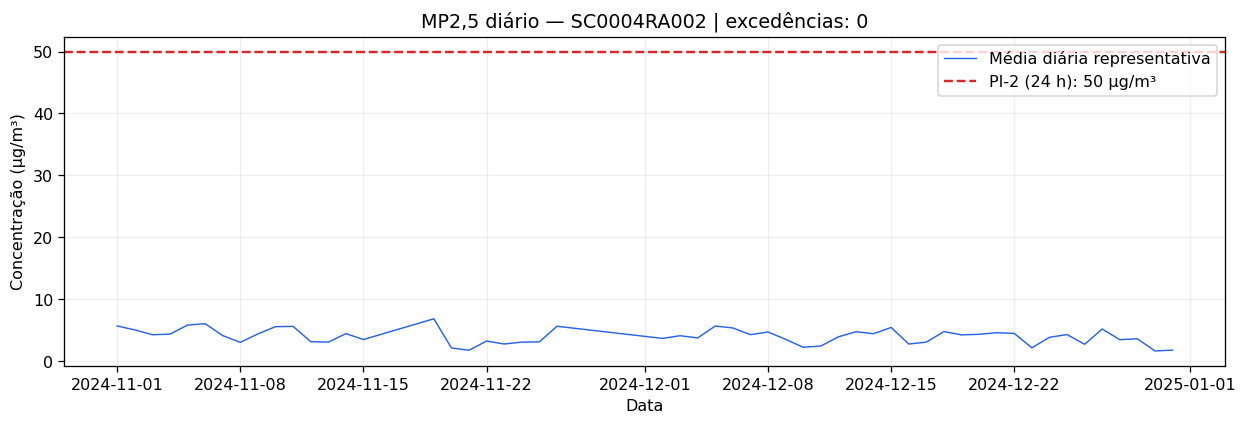

In [22]:
if serie_diaria.empty:
    print('Não há dados diários para gerar gráficos.')
else:
    for id_estacao, dados_estacao in serie_diaria.groupby(
        'ID_MMA_COMPLETO'
    ):
        fig, ax = plt.subplots(figsize=(11, 3.8))
        ax.plot(
            dados_estacao['data'],
            dados_estacao['MP25_UG_M3'],
            lw=0.9,
            color='#2563eb',
            label='Média diária representativa',
        )
        ax.axhline(
            PI2_DIA, color='#dc2626', linestyle='--', lw=1.5,
            label=f'PI-2 (24 h): {PI2_DIA:g} µg/m³',
        )

        # Excedência significa concentração estritamente acima do PI-2.
        n_excedencias = int(
            (dados_estacao['MP25_UG_M3'] > PI2_DIA).sum()
        )
        ax.set(
            title=f'MP2,5 diário — {id_estacao} '
                  f'| excedências: {n_excedencias}',
            xlabel='Data',
            ylabel='Concentração (µg/m³)',
        )
        ax.legend(loc='upper right')
        ax.grid(alpha=0.2)
        plt.tight_layout()

        # Exportação opcional:
        # DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
        # plt.savefig(
        #     DIR_FIGURAS / f'mp25_diario_{id_estacao}.png',
        #     dpi=180,
        # )
        plt.show()

### 3.2. Evolução anual calculada a partir das médias diárias

Em cada ano, calculamos a **média aritmética das médias diárias válidas** e a **fração de dias com dados representativos**. Isso não substitui os procedimentos formais de completude do relatório ou da autoridade ambiental. O gráfico anual distingue PI-2 (`17 µg/m³`) de PI-1 (`20 µg/m³`).

,ID_MMA_COMPLETO,ano,media_anual,dias_validos,dias_ano,cobertura_pct
0,SC0004RA002,2024,4.0,53,366,14.48


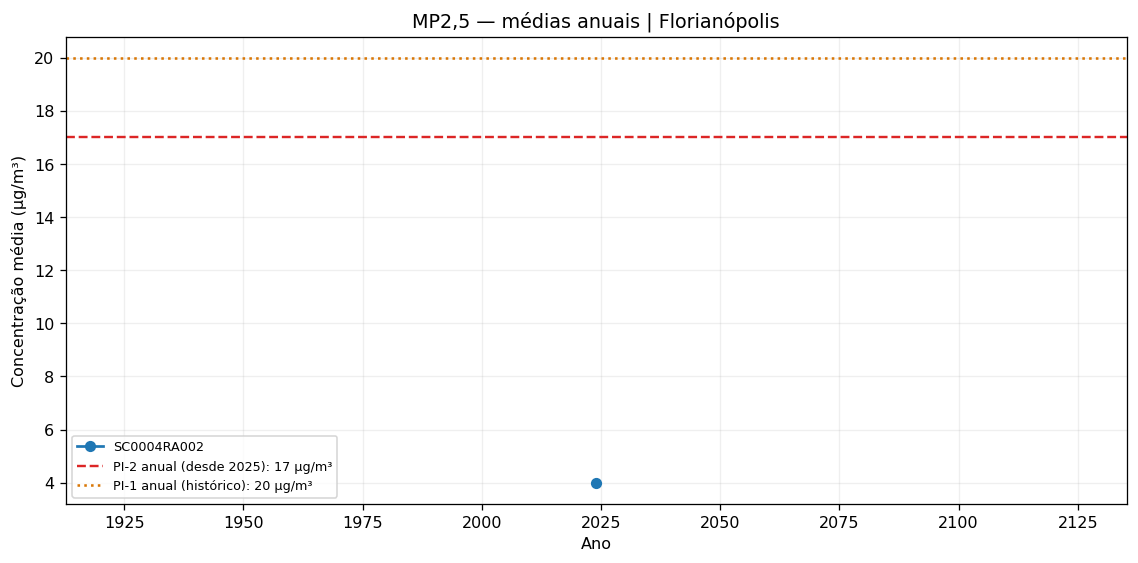

Observe cobertura_pct: anos incompletos não são suficientes para atestar conformidade com o padrão.


In [23]:
if serie_diaria.empty:
    serie_anual = pd.DataFrame(columns=[
        'ID_MMA_COMPLETO', 'ano', 'media_anual',
        'dias_validos', 'dias_ano', 'cobertura_pct',
    ])
    print('Sem série anual: nenhuma média diária disponível.')
else:
    dados_anuais = serie_diaria.copy()
    dados_anuais['ano'] = dados_anuais['data'].dt.year

    # A média anual é a média dos dias representativos de cada ano.
    serie_anual = (
        dados_anuais.groupby(['ID_MMA_COMPLETO', 'ano'], as_index=False)
        .agg(
            media_anual=('MP25_UG_M3', 'mean'),
            dias_validos=('data', 'nunique'),
        )
    )

    # A porcentagem usa 365 ou 366 dias conforme o ano civil.
    ultimo_dia_ano = pd.to_datetime(
        serie_anual['ano'].astype(str) + '-12-31'
    )
    serie_anual['dias_ano'] = np.where(
        ultimo_dia_ano.dt.is_leap_year, 366, 365
    )
    serie_anual['cobertura_pct'] = (
        100 * serie_anual['dias_validos'] / serie_anual['dias_ano']
    )

    # Exportação opcional das médias anuais:
    # DIR_TABELAS.mkdir(parents=True, exist_ok=True)
    # serie_anual.to_csv(
    #     DIR_TABELAS / f'mp25_anual_{CODIGO_IBGE}.csv',
    #     index=False,
    # )

    display(serie_anual.round(2))
    fig, ax = plt.subplots(figsize=(10, 5))
    for id_estacao, dados_estacao in serie_anual.groupby(
        'ID_MMA_COMPLETO'
    ):
        ax.plot(
            dados_estacao['ano'], dados_estacao['media_anual'],
            marker='o', linewidth=1.7, label=id_estacao,
        )

    ax.axhline(
        PI2_ANO, color='#dc2626', linestyle='--', lw=1.5,
        label=f'PI-2 anual (desde 2025): {PI2_ANO:g} µg/m³',
    )
    ax.axhline(
        PI1_ANO, color='#d97706', linestyle=':', lw=1.6,
        label=f'PI-1 anual (histórico): {PI1_ANO:g} µg/m³',
    )
    ax.set(
        title=f'MP2,5 — médias anuais | {NOME_MUNICIPIO}',
        xlabel='Ano', ylabel='Concentração média (µg/m³)',
    )
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, loc='best')
    plt.tight_layout()

    # Exportação opcional:
    # DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
    # plt.savefig(
    #     DIR_FIGURAS / f'mp25_anual_{CODIGO_IBGE}.png',
    #     dpi=180,
    # )
    plt.show()
    print(
        'Observe cobertura_pct: anos incompletos não são suficientes '
        'para atestar conformidade com o padrão.'
    )

### Onde reproduzir esta análise sem escrever código?

A [versão digital interativa do relatório](https://arquivos.lcqar.ufsc.br/br-airquality-report/intro.html)
permite visualizar **estações, séries históricas, médias diárias e
agregações temporais**, selecionando municípios e poluentes.

---

### Para discussão

- A principal fonte de **MP₂,₅ primário emitido** explica
  necessariamente a maior concentração medida em uma estação? Por quê?
- Quais as consequências da resolução de **20 km × 20 km** para
  municípios pequenos?
- A fonte majoritária de MP₂,₅ também é a de **NOₓ expresso em
  NO₂-equivalente**?
- Como classe, situação operacional e completude de dados das estações
  influenciam a interpretação dos resultados?

### Referências de apoio

- HOINASKI et al. (2024), [*Brazilian Atmospheric Inventories — BRAIN*](https://essd.copernicus.org/articles/16/2385/2024/).
- IBGE, [Malhas Municipais 2025](https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2025/Brasil/BR_Municipios_2025.zip).
- LCQAr/UFSC, [Relatório Anual de Acompanhamento da Qualidade do Ar (versão interativa)](https://arquivos.lcqar.ufsc.br/br-airquality-report/intro.html).
- CONAMA, [Resolução nº 506/2024](https://conama.mma.gov.br/index.php?option=com_sisconama&view=atonormativo&id=756).
- CMAS, [metadados e parâmetros de grade I/O API](https://cmascenter.org/ioapi/documentation/all_versions/html/GRIDS.html).